# 02 - Keyword Cleaning & EDA

Loads `raw_articles.pkl` and applies keyword cleaning.
All optional steps can be turned on/off independently.

In [1]:
import pandas as pd
import re
import unicodedata
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from wordcloud import WordCloud

CWD = Path.cwd()
PROJECT_ROOT = CWD if (CWD / 'big_data').exists() else CWD.parent
BIG_DATA = PROJECT_ROOT / 'big_data'
DATA_DIR = PROJECT_ROOT / 'data'

PICKLE_IN = BIG_DATA / 'baseline' / 'pickle' / 'raw_articles.pkl'
PICKLE_OUT = BIG_DATA / 'baseline' / 'pickle' / 'clean_articles.pkl'

df_raw = pd.read_pickle(PICKLE_IN)
print(f"Loaded: {df_raw.shape[0]} articles, {df_raw.shape[1]} columns")
df_raw.head(2)


Loaded: 44393 articles, 16 columns


,filename,pmcid,doi,journal,year,authors,title,keywords,abstract,introduction,methods,results,discussion,conclusion,tables,metadata_junk
0,PMC3000446.xml,PMC3000446,10.1136/bjo.2010.182402,Br J Ophthalmol The British Journal of Ophthal...,2010,['Crosby'] ['Michelle B']; ['Yang'] ['Hua']; [...,Serum vascular endothelial growth factor (VEGF...,Pathology; neoplasia,A preliminary animal study was performed to de...,Uveal melanoma is the most common primary mali...,"B16LS9 cells (courtesy of D. Rusciano, Friedri...",Serum VEGF levels rose after inoculation of C5...,We have shown that serum VEGF levels rise over...,,,
1,PMC3000472.xml,PMC3000472,10.1007/s00249-010-0624-9,Eur Biophys J European Biophysics Journal,2010,['Caorsi'] ['Valentina']; ['Ushakov'] ['Dmtry ...,FRET characterisation for cross-bridge dynamic...,Acceptor photobleaching; Actomyosin interactio...,In this work we demonstrate for the first time...,Myosin is a motor protein which converts chemi...,Table O -{ N -[3-(7-diethylaminocoumarin-3-car...,All the FRET experiments described herein were...,All the FRET experiments described herein were...,FRET measurements on single permeabilised musc...,Relaxing solution Pre-rigor solution Ca-rigor ...,\n[unmapped: appendix: single fret population ...


In [ ]:
# artefacts in authors removed;  cleaning in data_extraction py-script was incomplete

df_raw['authors']=df_raw['authors'].str.replace(r"\['|'\]", "", regex=True)
df_raw.iloc[1000:1004,0:8].T

def fix_title(t):
    if len(t) > 300:
        match = re.search(r'^(.{10,300}?)\s{2,}', t)
        return match.group(1).strip() if match else t[:300]
    return t

df_raw['title'].apply(fix_title)


,1000,1001,1002,1003
filename,PMC3020580.xml,PMC3020347.xml,PMC3020346.xml,PMC3020296.xml
pmcid,PMC3020580,PMC3020347,PMC3020346,PMC3020296
doi,10.1093/cercor/bhq095,10.1590/S1807-59322010001200019,10.1590/S1807-59322010001200018,10.1007/s00270-010-0004-y
journal,"Cereb Cortex Cerebral Cortex (New York, NY)",Clinics (Sao Paulo) Clinics,Clinics (Sao Paulo) Clinics,Cardiovasc Intervent Radiol Cardiovascular and...
year,2011,2010,2010,2010
authors,Nagy Zoltan; Lagercrantz Hugo; Hutton Chloe,Piratello Aline Cristina; Moraes-Silva Ivana; ...,Valenti Vitor E; de Abreu Luiz Carlos; Sato Mo...,Reekers Jim A.; Müller-Hülsbeck Stefan; Libich...
title,Effects of Preterm Birth on Cortical Thickness...,Renin angiotensin system and cardiac hypertrop...,"ATZ (3‐amino‐1,2,4‐triazole) injected into the...",CIRSE Vascular Closure Device Registry Local v...
keywords,MRI; brain; cerebral cortex; cortical thicknes...,Angiotensins; Collagen; Left ventricular hyper...,Cardiovascular System; Catalase; Medulla Oblon...,Closure device; Interventional radiology; Punc...


## 1 - clean_text helper

In [3]:
# 1. removes Unicode symbols by encoding UTF -> two ascii, first is taken the later is dropped: é -> e and ´ -> e remains
#  2. removes characters that are not characters or digits except for decimal '.'
# 3. white space characters
def clean_text(text: str) -> str:
    """Unicode normalise, ASCII-only, keep decimal points."""
    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'(\d)\.(\d)', r'\1T1E2M3P4\2', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text) #replace of .; etc to space (single or more), but white space remains (still) 
    text = text.replace('T1E2M3P4', '.')
    text = re.sub(r'\s+', ' ', text).strip() #now, all white space is replaced by  1x space
    return text

## 2 - Keyword Cleaning

**first: simple** 

blacklist only - no subj-group splitting yet.
Enable splitting later if baseline F1 is poor.

In [4]:
# --- Noise filter ---
# noise_words : single tokens -> checked against individual words of a keyword
# noise_phrases: multi-word strings -> checked against the full keyword string
noise_words = {
    'research', 'article', 'articles', 'review', 'reviews',
    'original', 'study', 'paper', 'papers', 'report', 'reports',
    'investigation', 'chemistry', 'clinical', 'full',
    'dentistry', 'science',
}
noise_phrases = {
    'biological sciences', 'case report', 'original research',
    'original article', 'original investigation',
    'methods online', 'scientific papers', 'clinical science'
}

df = df_raw.copy()

def filter_keywords(kwd_str: str) -> list:
    if not isinstance(kwd_str, str):
        return []
    result = []
    for k in kwd_str.split(';'):
        k = k.strip()
        if not k:
            continue
        k_lower = k.lower()
        k_words = set(k_lower.split())
        if k_lower not in noise_phrases and not any(n in k_words for n in noise_words):
            result.append(k)
    return result

df['kwd_lst']    = df['keywords'].apply(filter_keywords)
df['kwd_lst_cl'] = df['kwd_lst'].apply(lambda kwds: [clean_text(k).lower() for k in kwds])
df['n_keywords'] = df['kwd_lst_cl'].apply(len)

print(f"Articles with >= 1 keyword: {(df['n_keywords'] > 0).sum()}")
df[['keywords', 'kwd_lst', 'n_keywords']].head(3)

Articles with >= 1 keyword: 44364


,keywords,kwd_lst,n_keywords
0,Pathology; neoplasia,"[Pathology, neoplasia]",2
1,Acceptor photobleaching; Actomyosin interactio...,"[Acceptor photobleaching, Actomyosin interacti...",6
2,Fatty acids; Heart; Phophospholipids; Rat; Sex...,"[Fatty acids, Heart, Phophospholipids, Rat, Se...",6


## 3 - Keyword Frequency Filter

Filter by minimum corpus frequency. OCIS-coded keywords excluded. Articles with no remaining valid keywords are dropped.

In [5]:
# Flatten all cleaned keywords
lst_keys = [key for kws in df["kwd_lst_cl"].dropna() for key in kws if key]

keyword_counts = pd.Series(lst_keys).value_counts()

print(f"Total unique      : {len(keyword_counts)}")
print(f"Nach min_freq=2   : {(keyword_counts >= 2).sum()}")
print(f"Nach min_freq=10  : {(keyword_counts >= 10).sum()}")
print(f"Nach min_freq=20  : {(keyword_counts >= 20).sum()}")

Total unique      : 87666
Nach min_freq=2   : 23325
Nach min_freq=10  : 3012
Nach min_freq=20  : 1194


In [6]:
# Tradeoff: keywords retained vs articles lost per threshold
for mf in [5, 10, 20]:
    valid = set(keyword_counts[keyword_counts >= mf].index)
    valid_no_ocis = {k for k in valid if not re.match(r"^\d+\.\d+", k)}
    empty = df["kwd_lst_cl"].apply(
        lambda kws: len([k for k in kws if k in valid_no_ocis]) == 0 if isinstance(kws, list) else True
    ).sum()
    print(f"min_freq={mf:>2}: {len(valid_no_ocis):>5} keywords retained | {100*empty/len(df):.1f}% articles lost")

min_freq= 5:  6904 keywords retained | 10.2% articles lost
min_freq=10:  2970 keywords retained | 18.0% articles lost
min_freq=20:  1177 keywords retained | 29.4% articles lost


valid_keywords: 2970
Articles dropped : 8003 (18.0%)
Articles retained: 36390


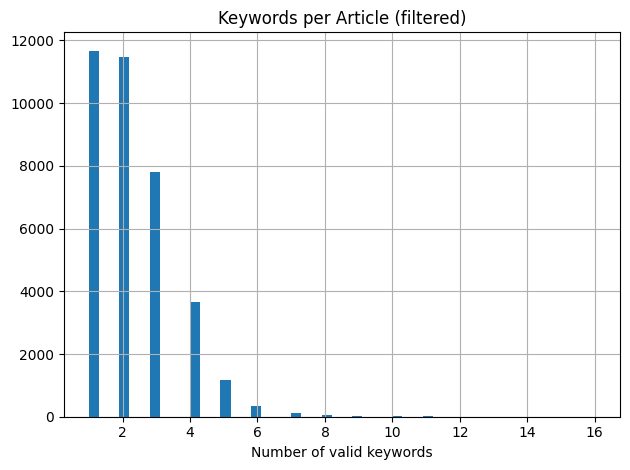

In [7]:
# Keywords with freq < 10 excluded: insufficient training samples per class
# -> class imbalance + overfitting risk
# OCIS-coded keywords (float prefix e.g. "170.6935 ...") excluded: journal-specific
min_freq = 10

valid_keywords = set(keyword_counts[keyword_counts >= min_freq].index)
valid_keywords = {k for k in valid_keywords if not re.match(r"^\d+\.\d+", k)}
print(f"valid_keywords: {len(valid_keywords)}")

df["keywords_filtered"] = df["kwd_lst_cl"].apply(
    lambda kws: [k for k in kws if k in valid_keywords] if isinstance(kws, list) else []
)

n_before = len(df)
df = df[df["keywords_filtered"].apply(len) > 0].copy()
print(f"Articles dropped : {n_before - len(df)} ({100*(n_before-len(df))/n_before:.1f}%)")
print(f"Articles retained: {len(df)}")

df["keywords_filtered"].apply(len).hist(bins=50)
plt.title("Keywords per Article (filtered)")
plt.xlabel("Number of valid keywords")
plt.tight_layout()
plt.show()

## 4 - EDA Plots

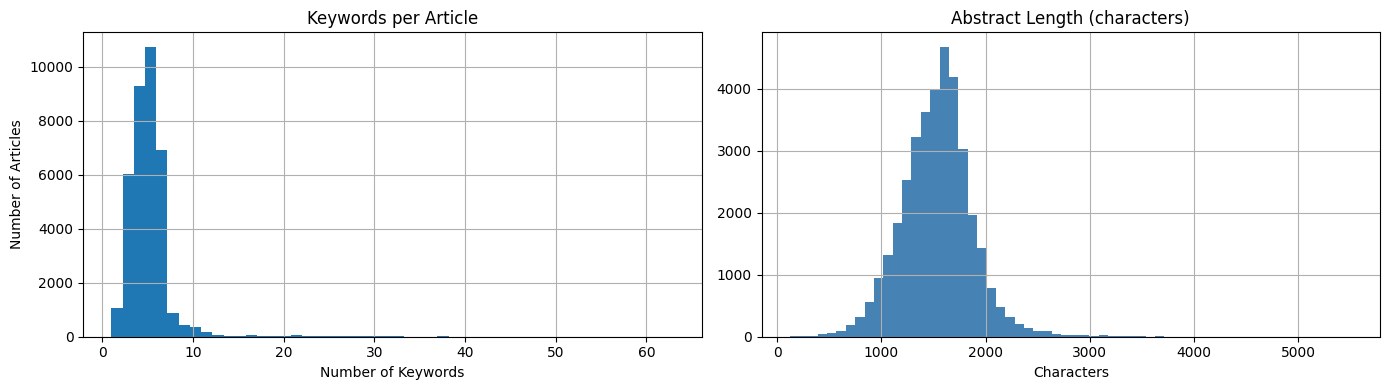

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Keywords per article
df['n_keywords'].hist(bins=50, ax=axes[0])
axes[0].set_title('Keywords per Article')
axes[0].set_xlabel('Number of Keywords')
axes[0].set_ylabel('Number of Articles')

# Abstract length
df['abstract'].apply(len).hist(bins=60, ax=axes[1], color='steelblue')
axes[1].set_title('Abstract Length (characters)')
axes[1].set_xlabel('Characters')

plt.tight_layout()
plt.show()

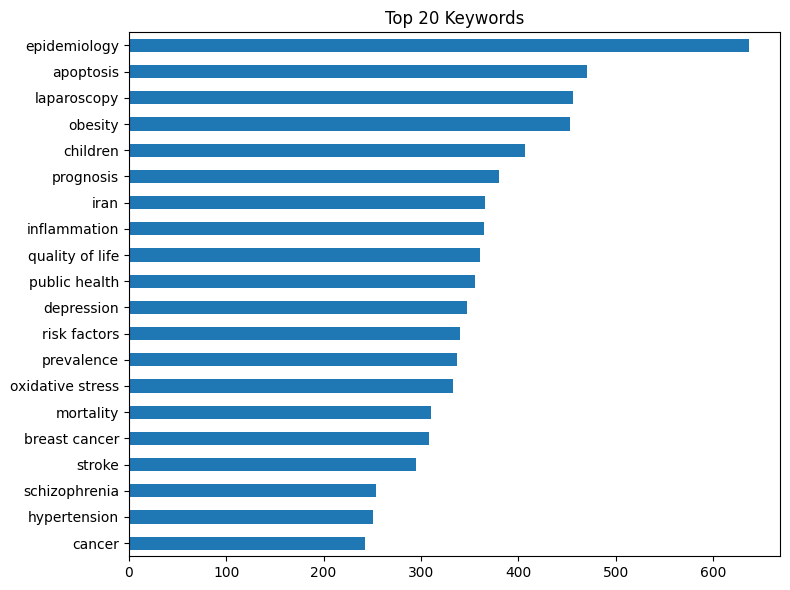

epidemiology        637
apoptosis           471
laparoscopy         456
obesity             453
children            407
prognosis           380
iran                366
inflammation        365
quality of life     361
public health       356
depression          347
risk factors        340
prevalence          337
oxidative stress    333
mortality           310
breast cancer       308
stroke              295
schizophrenia       254
hypertension        251
cancer              243
dtype: int64


In [10]:
# Top 20 keywords
all_kwds = [k for kwds in df['kwd_lst_cl'] for k in kwds]
top20 = pd.Series(dict(Counter(all_kwds).most_common(20)))
top20.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 20 Keywords')
plt.tight_layout()
plt.show()
print(top20.sort_values(ascending=False))

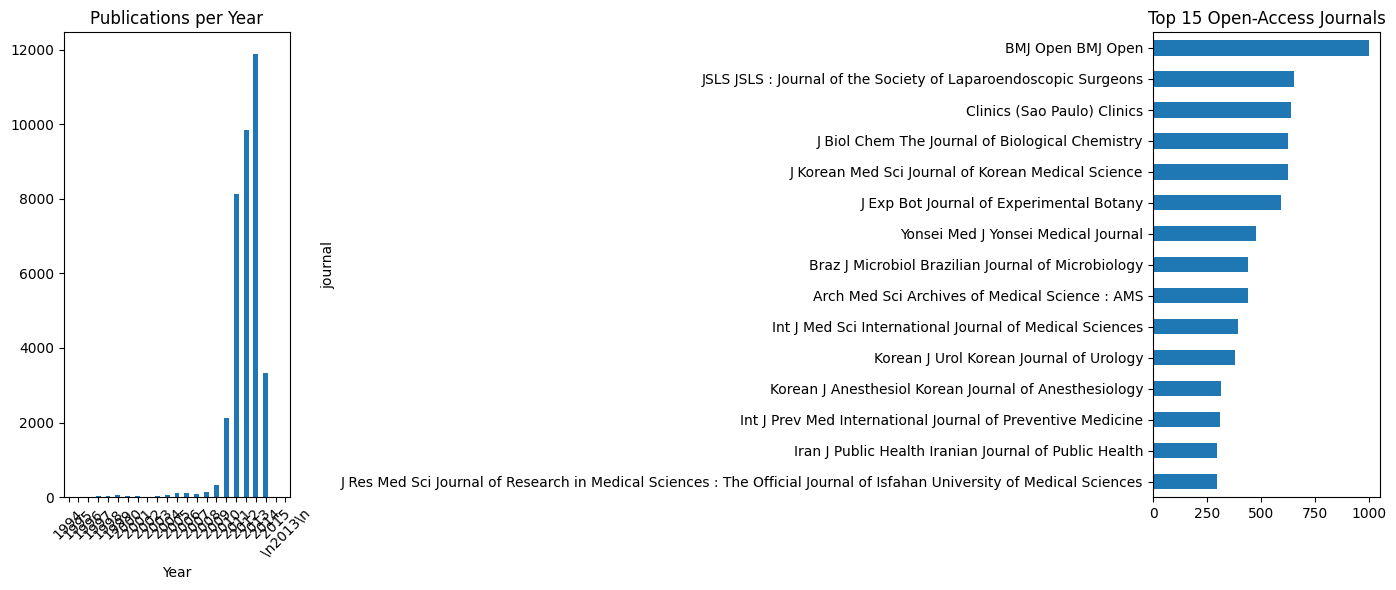

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 6))

# Publications per year
df['year'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Publications per Year')
axes[0].set_xlabel('Year')
axes[0].tick_params(axis='x', rotation=45)

# Top 15 journals
df['journal'].value_counts().head(15).sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_title('Top 15 Open-Access Journals')

plt.tight_layout()
plt.show()

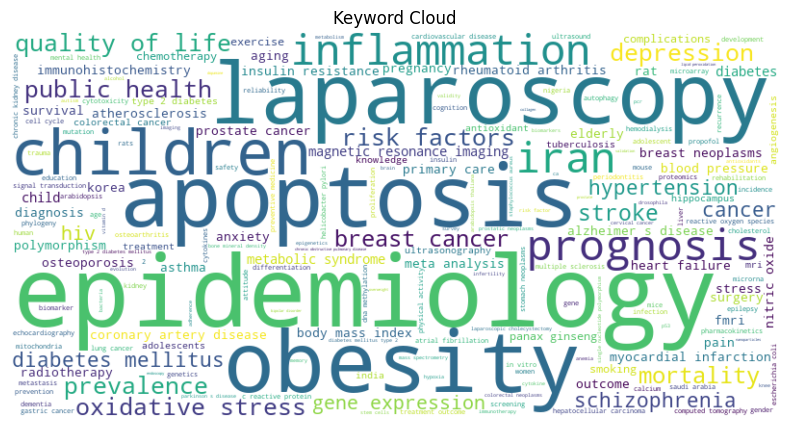

In [16]:
from wordcloud import WordCloud
from collections import Counter

all_kwds = [k for kwds in df['kwd_lst_cl'] for k in kwds]
freq = Counter(all_kwds)

wc = WordCloud(width=800, height=400, background_color='white')
wc.generate_from_frequencies(freq) 
plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Keyword Cloud')
plt.show()

## 5 - Save Cleaned Pickle

Only run after reviewing EDA above.

In [17]:
SAVE_CLEAN_PICKLE = True   # set True to save

if SAVE_CLEAN_PICKLE:
    PICKLE_OUT.parent.mkdir(parents=True, exist_ok=True)
    df.to_pickle(PICKLE_OUT)
    print(f"Saved: {PICKLE_OUT}  ({len(df)} articles)")
else:
    print("SAVE_CLEAN_PICKLE = False - nothing written.")

Saved: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\big_data\baseline\pickle\clean_articles.pkl  (36390 articles)
